# Model comparison and chosen models

**Deliverables 4 and 5:** the model comparison table on the validation set, and for each chosen model the test-set
median and 95th-percentile error, a predicted-vs-SPICE plot and the saved model file.

| Section | Content |
|---|---|
| 1. Model comparison (validation set) | every model type × case: R², median and 95th-percentile error (plus mean) |
| 2. Chosen models | the model chosen for each case, why, and its saved file |
| 3. Test-set results | the chosen models on the test set, computed here from the saved files |
| 4. Predicted vs SPICE | one parity plot per case (test set) |
| 5. Where the mean error comes from | how few rows cause the large mean errors, and why (test set) |

**How it works**
- The comparison table is read from the result files the training notebooks write (`validation_comparison_*.csv`
  in this folder).
- The chosen models are **loaded from `ML_Models/Saved_Models/`** with `ML_Models/Scripts/leakage_model.py` and evaluated
  here. The test set is used **only in this notebook**.
- Each device type has its own training notebook (`pmos_models.ipynb`, `nmos_models.ipynb`); a case whose
  notebook has not been run yet is listed as missing.

**Files written:** `test_results.csv` and `error_concentration.csv` (this folder) and `parity_<case>.png` (`ML_Models/Plots/`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "Data_Generation").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook from inside the DVD-Project repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "ML_Models" / "Scripts"))
from leakage_model import LeakageModel, OUTPUT_COLS, error_table, split_indices

DATA_DIR    = ROOT / "Data_Generation" / "Datasets"
RESULTS_DIR = ROOT / "ML_Models" / "Results"
MODEL_DIR   = ROOT / "ML_Models" / "Saved_Models"
PLOT_DIR    = ROOT / "ML_Models" / "Plots"
CASES = ["NMOS_ON", "NMOS_OFF", "PMOS_ON", "PMOS_OFF"]
MODEL_ORDER = ["Random forest", "XGBoost", "Polynomial (Ridge)", "MLP", "MLP + Kirchhoff loss"]
METRICS = ["R2 (log|I|)", "median err %", "95th pct err %", "mean err %"]

pd.set_option("display.float_format", lambda v: f"{v:.3g}")
BLUE, LIGHT_BLUE = "#2a78d6", "#9ec5f4"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 10, "font.size": 9, "legend.frameon": False,
})

## 1. Model comparison table — validation set

- **R²** on log10|I|
- **% error** = |I_pred / I_SPICE − 1| × 100, summarized by its **median**, **95th percentile** and **mean**
- Each value is the **average over the four currents** (id, ig, is, ib); the per-current values follow below.
- Rows are the four model types, plus the MLP trained with the Kirchhoff (physics-informed) loss as a variant.

In [2]:
files = sorted(RESULTS_DIR.glob("validation_comparison_*.csv"))
comparison = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print("result files:", ", ".join(f.name for f in files))
missing = [c for c in CASES if c not in set(comparison["case"])]
print("cases without results yet:", ", ".join(missing) if missing else "none")

avg = comparison[comparison["current"] == "average"]
table = avg.pivot_table(index="model", columns="case", values=METRICS)
table = table.swaplevel(axis=1)                                       # columns: (case, metric)
table = table.reindex(columns=[(c, m) for c in CASES for m in METRICS if (c, m) in table.columns])
table = table.reindex([m for m in MODEL_ORDER if m in table.index])
table

result files: validation_comparison_NMOS.csv, validation_comparison_PMOS.csv
cases without results yet: none


case                     NMOS_ON                                         \
                     R2 (log|I|) median err % 95th pct err % mean err %   
model                                                                     
Random forest              0.988         14.3           56.1       23.4   
XGBoost                    0.999         3.14           14.4       5.55   
Polynomial (Ridge)         0.996         5.79             28        9.2   
MLP                            1        0.239            1.3      0.543   
MLP + Kirchhoff loss           1        0.595           3.16       1.34   

case                    NMOS_OFF                                         \
                     R2 (log|I|) median err % 95th pct err % mean err %   
model                                                                     
Random forest               0.92         10.2           47.5        201   
XGBoost                    0.982         3.45           20.7       69.1   
Polynomial (Ridge)         0.869         13.7             67        244   
MLP                        0.976        0.397           2.96       8.52   
MLP + Kirchhoff loss        0.99        0.408           2.83       7.25   

case                     PMOS_ON                                         \
                     R2 (log|I|) median err % 95th pct err % mean err %   
model                                                                     
Random forest              0.988         14.2           54.4       20.3   
XGBoost                    0.999         2.86           12.6       4.37   
Polynomial (Ridge)         0.997         4.46           22.1       7.02   
MLP                            1        0.345           1.62      0.559   
MLP + Kirchhoff loss           1        0.426           2.15      0.761   

case                    PMOS_OFF                                         
                     R2 (log|I|) median err % 95th pct err % mean err %  
model                                                                    
Random forest              0.923         9.75           49.8       29.2  
XGBoost                    0.985         3.33           19.4       13.4  
Polynomial (Ridge)         0.868         14.6           77.3         70  
MLP                         0.99         0.33           2.02       1.83  
MLP + Kirchhoff loss       0.991        0.346           2.25        1.5

In [3]:
# per current: median and 95th-percentile error on the validation set
per_current = comparison[comparison["current"] != "average"].pivot_table(
    index=["case", "model"], columns="current", values=["median err %", "95th pct err %"])
per_current = per_current.swaplevel(axis=1)
per_current = per_current.reindex(columns=[(c, m) for c in OUTPUT_COLS for m in ["median err %", "95th pct err %"]])
per_current.reindex([(c, m) for c in CASES for m in MODEL_ORDER if (c, m) in per_current.index])

current                                 id                          ig  \
                              median err % 95th pct err % median err %   
case     model                                                           
NMOS_ON  Random forest                10.7           47.9         14.3   
         XGBoost                      2.14           14.5         2.54   
         Polynomial (Ridge)           4.37           19.8         9.76   
         MLP                         0.206           1.09        0.233   
         MLP + Kirchhoff loss         0.51           2.26        0.631   
NMOS_OFF Random forest                12.5           54.3         11.8   
         XGBoost                      5.18             37         3.16   
         Polynomial (Ridge)           24.7            134         2.06   
         MLP                         0.562           4.14        0.382   
         MLP + Kirchhoff loss        0.582           3.89        0.388   
PMOS_ON  Random forest                11.1           46.8         13.3   
         XGBoost                      1.86           12.5         2.29   
         Polynomial (Ridge)           4.01           13.3         5.25   
         MLP                         0.339           1.33        0.267   
         MLP + Kirchhoff loss        0.359           1.63        0.426   
PMOS_OFF Random forest                11.9           55.6         11.4   
         XGBoost                       5.1           33.4         3.16   
         Polynomial (Ridge)           25.6            125         1.99   
         MLP                         0.437           2.59        0.333   
         MLP + Kirchhoff loss         0.47           2.75        0.304   

current                                                is                 \
                              95th pct err % median err % 95th pct err %   
case     model                                                             
NMOS_ON  Random forest                  57.7         10.7           47.8   
         XGBoost                        9.71         2.16           15.4   
         Polynomial (Ridge)             48.5         4.36           20.2   
         MLP                            1.71        0.217           1.03   
         MLP + Kirchhoff loss           5.23        0.513           2.24   
NMOS_OFF Random forest                  51.1         12.9           54.9   
         XGBoost                        10.4         5.43           33.1   
         Polynomial (Ridge)              8.9         22.2           99.9   
         MLP                            2.22        0.554            3.5   
         MLP + Kirchhoff loss           2.19        0.552           3.37   
PMOS_ON  Random forest                  53.4         11.1           46.8   
         XGBoost                        8.62         1.88           12.8   
         Polynomial (Ridge)             45.6         4.03           13.1   
         MLP                            1.85        0.338           1.53   
         MLP + Kirchhoff loss           2.76        0.359           1.61   
PMOS_OFF Random forest                  54.6           12           58.7   
         XGBoost                        10.3         4.97           31.7   
         Polynomial (Ridge)             8.37         25.9            152   
         MLP                            1.63        0.429           2.66   
         MLP + Kirchhoff loss           1.77        0.468              3   

current                                 ib                 
                              median err % 95th pct err %  
case     model                                             
NMOS_ON  Random forest                21.6           70.9  
         XGBoost                      5.71           18.1  
         Polynomial (Ridge)           4.65           23.3  
         MLP                         0.302           1.38  
         MLP + Kirchhoff loss        0.726            2.9  
NMOS_OFF Random forest                3.41           29.6  
        

## 2. Chosen models

**Rule:** for each case, the model with the lowest validation **mean** error (average over the four currents), because
the project targets mean accuracy. Each saved file is self-contained: network weights, hidden layers, feature list and
both scalers.

In [4]:
models, rows = {}, []
for case in CASES:
    path = MODEL_DIR / f"{case}.pt"
    if not path.exists():
        rows.append({"case": case, "model": "— not saved yet —"})
        continue
    m = LeakageModel(path)
    models[case] = m
    v = m.info["validation"]
    rows.append({"case": case, "model": m.info["model"], "hidden layers": "-".join(map(str, m.info["hidden"])),
                 "Kirchhoff λ": m.info.get("kirchhoff_lambda", 0.0),
                 "val median err %": v["median err %"], "val 95th pct err %": v["95th pct err %"], "val mean err %": v["mean err %"],
                 "file": str(path.relative_to(ROOT)), "size kB": path.stat().st_size / 1024})
pd.DataFrame(rows).set_index("case")

,model,hidden layers,Kirchhoff λ,val median err %,val 95th pct err %,val mean err %,file,size kB
case,,,,,,,,
NMOS_ON,MLP,128-64-32-32,0,0.239,1.3,0.543,ML_Models/Saved_Models/NMOS_ON.pt,62.8
NMOS_OFF,MLP + Kirchhoff loss,128-64-32-16,10,0.408,2.83,7.25,ML_Models/Saved_Models/NMOS_OFF.pt,61
PMOS_ON,MLP,128-64-32-16,0,0.345,1.62,0.559,ML_Models/Saved_Models/PMOS_ON.pt,60.4
PMOS_OFF,MLP + Kirchhoff loss,128-64-32-32,30,0.346,2.25,1.5,ML_Models/Saved_Models/PMOS_OFF.pt,63.3


## 3. Test-set results

The test set is the same 10 % (2,000 samples) as in training: the 80 / 10 / 10 split is rebuilt here from the dataset
with the same seed. It was not used for training or for choosing any setting.

First, a **reproduction check**: the validation error recomputed here from the saved file must equal the value stored
by the training notebook, which proves that the file holds exactly the trained model.

In [5]:
test_tables, check, PRED = {}, [], {}
for case, m in models.items():
    df = pd.read_csv(DATA_DIR / m.info["dataset"])
    Y_log = np.log10(df[OUTPUT_COLS].abs()).values
    idx_train, idx_val, idx_test = split_indices(len(df), m.info["seed"])
    val = error_table(Y_log[idx_val], m.predict_log(df.iloc[idx_val])).loc["average"]
    check.append({"case": case, "val mean err % (training notebook)": m.info["validation"]["mean err %"],
                  "val mean err % (recomputed from file)": val["mean err %"],
                  "match": bool(np.isclose(val["mean err %"], m.info["validation"]["mean err %"], rtol=1e-4))})
    pred_test = m.predict_log(df.iloc[idx_test])
    test_tables[case] = error_table(Y_log[idx_test], pred_test)
    PRED[case] = (Y_log[idx_test], pred_test)
pd.DataFrame(check).set_index("case")

,val mean err % (training notebook),val mean err % (recomputed from file),match
case,,,
NMOS_ON,0.543,0.543,True
NMOS_OFF,7.25,7.25,True
PMOS_ON,0.559,0.559,True
PMOS_OFF,1.5,1.5,True


In [6]:
test_results = pd.concat(test_tables, names=["case", "current"])
test_results.to_csv(RESULTS_DIR / "test_results.csv")

# summary: chosen model per case, validation vs test (average over the four currents)
summary = pd.DataFrame({case: {"model": models[case].info["model"],
                               "val median err %": models[case].info["validation"]["median err %"],
                               "test median err %": t.loc["average", "median err %"],
                               "val 95th pct err %": models[case].info["validation"]["95th pct err %"],
                               "test 95th pct err %": t.loc["average", "95th pct err %"],
                               "test mean err %": t.loc["average", "mean err %"],
                               "test R2 (log|I|)": t.loc["average", "R2 (log|I|)"]}
                        for case, t in test_tables.items()}).T
display(summary)

# test set, per current
test_results

,model,val median err %,test median err %,val 95th pct err %,test 95th pct err %,test mean err %,test R2 (log|I|)
NMOS_ON,MLP,0.239,0.225,1.3,1.27,0.771,1
NMOS_OFF,MLP + Kirchhoff loss,0.408,0.397,2.83,2.6,6.67,0.985
PMOS_ON,MLP,0.345,0.348,1.62,1.56,0.651,1
PMOS_OFF,MLP + Kirchhoff loss,0.346,0.357,2.25,2.13,1.3,0.992


R2 (log|I|)  mean err %  median err %  95th pct err %
case     current                                                       
NMOS_ON  id                 1        0.72         0.203            1.02
         ig                 1       0.729         0.232            1.64
         is             0.999        1.21         0.204            1.09
         ib                 1       0.425         0.261            1.33
         average            1       0.771         0.225            1.27
NMOS_OFF id             0.995        4.83         0.554            3.58
         ig                 1        0.75         0.382            1.97
         is             0.994        20.3         0.544            3.26
         ib             0.952       0.802         0.111             1.6
         average        0.985        6.67         0.397             2.6
PMOS_ON  id             0.999       0.916         0.342            1.34
         ig                 1        0.54         0.276            1.73
         is                 1       0.507         0.337            1.39
         ib                 1       0.641         0.435            1.79
         average            1       0.651         0.348            1.56
PMOS_OFF id             0.997        2.17         0.495             2.9
         ig             0.999       0.781         0.312            1.68
         is             0.999        1.18         0.478            2.67
         ib             0.972        1.07         0.145            1.27
         average        0.992         1.3         0.357            2.13

## 4. Predicted vs SPICE — test set

Each point is one test sample; the dashed line is a perfect prediction. Axes are logarithmic because the currents
span many decades. Current magnitudes are shown; the signs are handled separately in Part B.

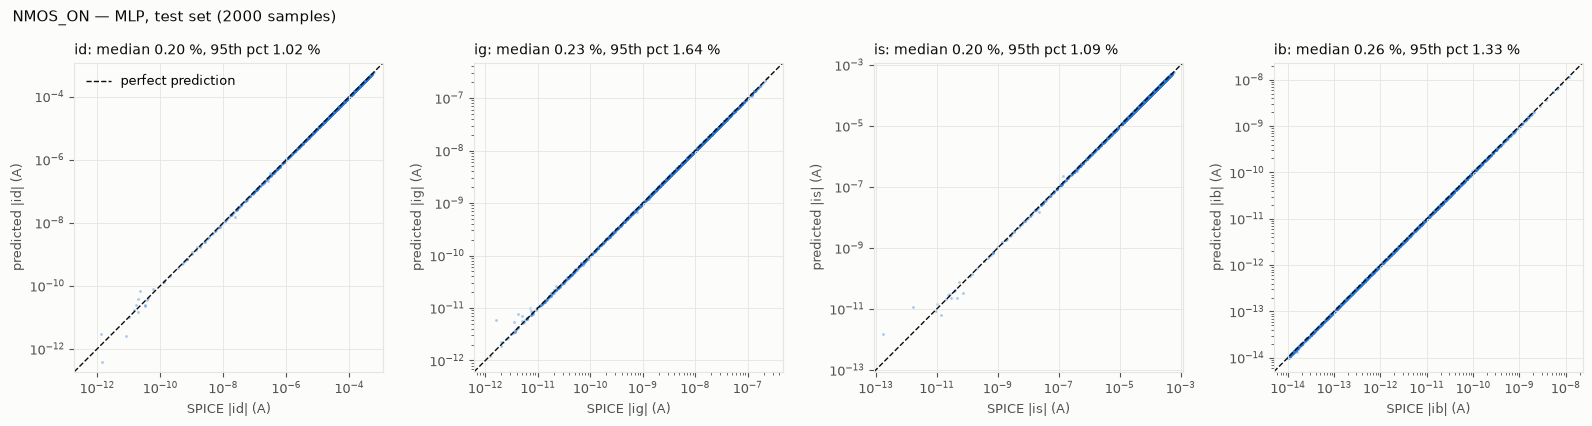

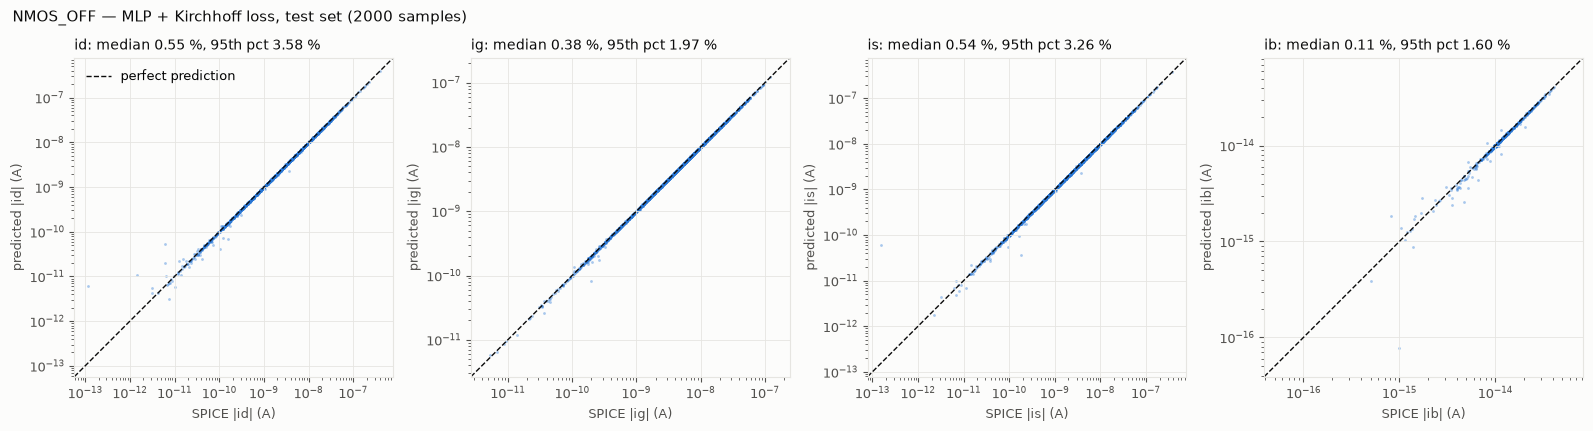

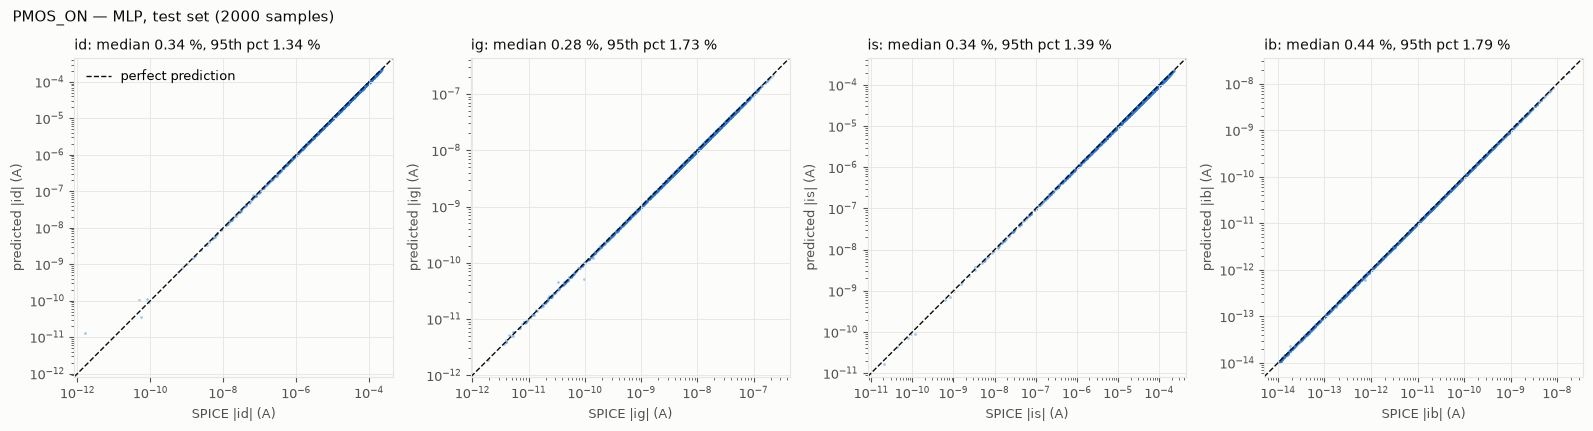

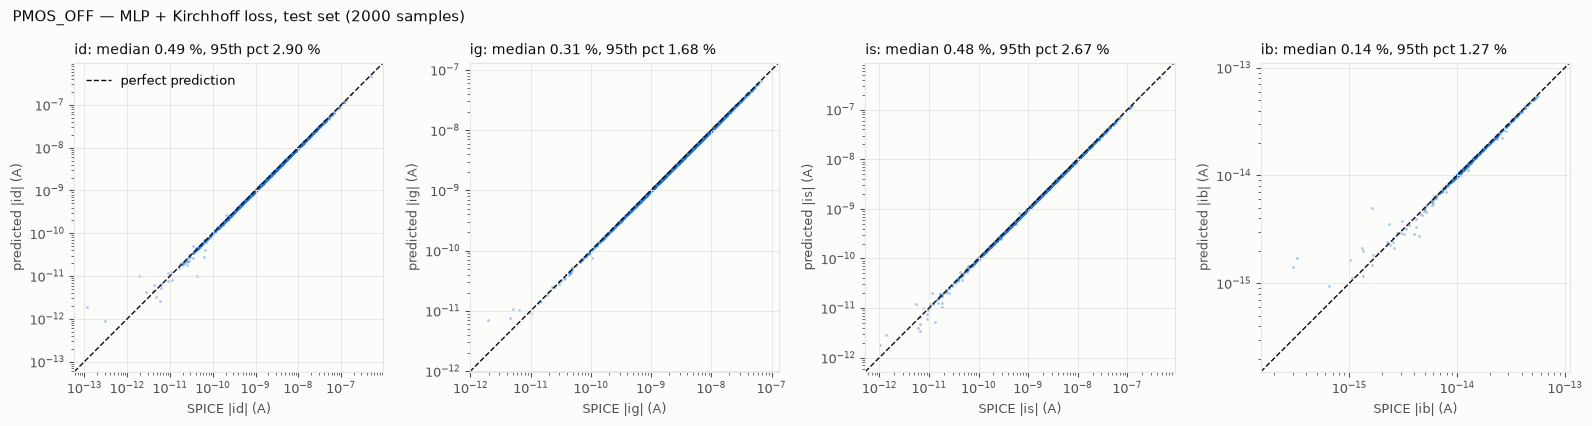

In [7]:
for case, (Y_true, Y_pred) in PRED.items():
    t = test_tables[case]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
    for k, (ax, c) in enumerate(zip(axes, OUTPUT_COLS)):
        x, y = 10 ** Y_true[:, k], 10 ** Y_pred[:, k]
        lo, hi = min(x.min(), y.min()) / 2, max(x.max(), y.max()) * 2
        ax.plot([lo, hi], [lo, hi], color=INK, lw=1, ls="--", label="perfect prediction")
        ax.scatter(x, y, s=4, alpha=0.4, color=BLUE, linewidths=0, rasterized=True)
        ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi), aspect="equal",
               xlabel=f"SPICE |{c}| (A)", ylabel=f"predicted |{c}| (A)")
        ax.set_title(f"{c}: median {t.loc[c, 'median err %']:.2f} %, 95th pct {t.loc[c, '95th pct err %']:.2f} %", loc="left")
    axes[0].legend(loc="upper left")
    fig.suptitle(f"{case} — {models[case].info['model']}, test set ({len(Y_true)} samples)",
                 color=INK, fontsize=11, x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"parity_{case}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 5. Where the mean error comes from

The mean of a % error is easily dominated by a few rows: if the SPICE current of one sample is tiny, a small error in
its log becomes a huge % error. This section measures how much of each mean error comes from the **5 worst rows** (0.25 %
of the 2,000 test rows) and what those rows look like. It is a diagnosis only: nothing here is used to select or change a model.

- `|I| / largest current` is the size of one terminal current relative to the largest current of the same sample.
  A value near 0 means the current is almost cancelled by the others (e.g. the drain channel leakage and the gate / junction
  leakage flowing in opposite directions).
- `SPICE Kirchhoff residual / |I|` compares the SPICE data's own inconsistency, |Id + Ig + Is + Ib|, with the target
  current. When it approaches 1, the target is at the numerical precision of the SPICE solution (the data check shows the
  residual is about 1e-6 of the largest current), so no model can predict it to better than that.


In [8]:
# 5a. share of each mean error that comes from the 5 worst test rows
rows = []
for case, (Y_true, Y_pred) in PRED.items():
    err = np.abs(10 ** (Y_pred - Y_true) - 1) * 100                         # % error, shape (n, 4)
    for k, c in enumerate(OUTPUT_COLS):
        e = np.sort(err[:, k])[::-1]
        rows.append({"case": case, "current": c, "mean err %": e.mean(), "median err %": np.median(e),
                     "rows with err > 100 %": int((e > 100).sum()),
                     "mean err % without 5 worst rows": e[5:].mean(),
                     "share of mean from 5 worst rows": e[:5].sum() / e.sum()})
concentration = pd.DataFrame(rows).set_index(["case", "current"])
concentration.to_csv(RESULTS_DIR / "error_concentration.csv")
concentration


mean err %  median err %  rows with err > 100 %  \
case     current                                                    
NMOS_ON  id             0.72         0.203                      2   
         ig            0.729         0.232                      1   
         is             1.21         0.204                      2   
         ib            0.425         0.261                      0   
NMOS_OFF id             4.83         0.554                      4   
         ig             0.75         0.382                      0   
         is             20.3         0.544                      1   
         ib            0.802         0.111                      1   
PMOS_ON  id            0.916         0.342                      2   
         ig             0.54         0.276                      0   
         is            0.507         0.337                      0   
         ib            0.641         0.435                      0   
PMOS_OFF id             2.17         0.495                      3   
         ig            0.781         0.312                      2   
         is             1.18         0.478                      2   
         ib             1.07         0.145                      3   

                  mean err % without 5 worst rows  \
case     current                                    
NMOS_ON  id                                 0.453   
         ig                                 0.483   
         is                                 0.465   
         ib                                 0.407   
NMOS_OFF id                                  1.34   
         ig                                 0.667   
         is                                  1.07   
         ib                                  0.62   
PMOS_ON  id                                 0.477   
         ig                                 0.478   
         is                                 0.471   
         ib                                  0.61   
PMOS_OFF id                                  1.03   
         ig                                 0.522   
         is                                 0.964   
         ib                                 0.508   

                  share of mean from 5 worst rows  
case     current                                   
NMOS_ON  id                                 0.373  
         ig                                 0.339  
         is                                 0.617  
         ib                                 0.046  
NMOS_OFF id                                 0.722  
         ig                                 0.112  
         is                                 0.948  
         ib                                 0.229  
PMOS_ON  id                                 0.481  
         ig                                 0.116  
         is                                0.0729  
         ib                                0.0513  
PMOS_OFF id                                 0.525  
         ig                                 0.334  
         is                                 0.187  
         ib                                 0.526

In [9]:
# 5b. error against how far id / is are cancelled by the other currents
#     held-out rows = validation + test (4,000 rows, never trained on); only id and is, the terminals whose signed
#     current can change sign (ig and ib keep one sign and are naturally small next to the channel current)
BINS   = [0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0001]
LABELS = ["< 0.01 %", "0.01 - 0.1 %", "0.1 - 1 %", "1 - 10 %", "10 - 100 %"]
tables, worst = {}, []
for case, m in models.items():
    df = pd.read_csv(DATA_DIR / m.info["dataset"])
    _, idx_val, idx_test = split_indices(len(df), m.info["seed"])
    idx = np.concatenate([idx_val, idx_test])
    I = df[OUTPUT_COLS].iloc[idx]
    ratio = I.abs().div(I.abs().max(axis=1), axis=0).values[:, [0, 2]]       # |I_k| / largest current of the sample
    err = np.abs(10 ** (m.predict_log(df.iloc[idx]) - np.log10(I.abs().values)) - 1)[:, [0, 2]] * 100
    bins = pd.cut(pd.Series(ratio.ravel()), BINS, labels=LABELS)
    tables[case] = (pd.DataFrame({"err": err.ravel(), "bin": bins})
                    .groupby("bin", observed=True)["err"].agg(["count", "mean", "median", "max"]))

    # the 3 worst (row, current) pairs of the test set, with the SPICE data's own Kirchhoff residual
    It = df[OUTPUT_COLS].iloc[idx_test]
    Y_true, Y_pred = PRED[case]
    e_test = np.abs(10 ** (Y_pred - Y_true) - 1) * 100
    for flat in np.argsort(e_test.ravel())[::-1][:3]:
        r, k = divmod(flat, len(OUTPUT_COLS))
        row = It.iloc[r]
        worst.append({"case": case, "row in dataset": int(idx_test[r]), "current": OUTPUT_COLS[k],
                      "|I| (A)": abs(row.iloc[k]), "largest current (A)": row.abs().max(),
                      "|I| / largest": abs(row.iloc[k]) / row.abs().max(),
                      "SPICE Kirchhoff residual / |I|": abs(row.sum()) / abs(row.iloc[k]), "error %": e_test[r, k]})
display(pd.concat(tables, names=["case", "|I| / largest current"]))
pd.DataFrame(worst).set_index(["case", "row in dataset"])


count     mean   median      max
case     |I| / largest current                                  
NMOS_ON  1 - 10 %                   2      267      267      492
         10 - 100 %              7998    0.708    0.208      739
NMOS_OFF < 0.01 %                   3 2.82e+04 3.82e+04 4.12e+04
         0.01 - 0.1 %               7 1.03e+03      213 4.98e+03
         0.1 - 1 %                 68     40.5     6.78      936
         1 - 10 %                 859     4.01    0.945      791
         10 - 100 %              7063    0.939     0.52     79.7
PMOS_ON  1 - 10 %                   1      679      679      679
         10 - 100 %              7999     0.54     0.34      177
PMOS_OFF < 0.01 %                   1 1.54e+03 1.54e+03 1.54e+03
         0.01 - 0.1 %              12      386      177 1.36e+03
         0.1 - 1 %                 51     42.8     23.9      311
         1 - 10 %                 637     2.44        1     55.6
         10 - 100 %              7299    0.758    0.448     79.3

current  |I| (A)  largest current (A)  |I| / largest  \
case     row in dataset                                                        
NMOS_ON  19570               is 1.75e-13             1.59e-12           0.11   
         15989               is 1.71e-12             1.21e-11          0.141   
         19570               ig 1.59e-12             1.59e-12              1   
NMOS_OFF 13855               is 1.57e-13             5.29e-09       2.97e-05   
         522                 id 1.14e-13             2.29e-09       4.99e-05   
         10269               id 5.98e-12             1.83e-10         0.0327   
PMOS_ON  7987                id 1.64e-12             2.18e-11         0.0752   
         14218               id 4.78e-11             8.06e-11          0.593   
         16053               ig 9.85e-11             9.85e-11              1   
PMOS_OFF 11770               id 1.16e-13             1.47e-09       7.89e-05   
         12811               ib  3.3e-16             3.73e-09       8.84e-08   
         595                 id 1.94e-12             8.82e-09        0.00022   

                         SPICE Kirchhoff residual / |I|  error %  
case     row in dataset                                           
NMOS_ON  19570                                  0.00028      739  
         15989                                 0.000259      587  
         19570                                 3.08e-05      278  
NMOS_OFF 13855                                   0.0193 3.82e+04  
         522                                     0.0493 5.28e+03  
         10269                                 0.000112      791  
PMOS_ON  7987                                  2.14e-05      679  
         14218                                 9.62e-07      113  
         16053                                 8.49e-07     47.9  
PMOS_OFF 11770                                   0.0551 1.54e+03  
         12811                                     2.03      416  
         595                                    0.00167      411

**Reading the result**

- **A handful of rows decides the mean.** On the test set the 5 worst rows (0.25 % of the rows) account for 72 % of the
  NMOS_OFF mean error of `id` (4.8 % → 1.3 % without them) and 95 % of the mean error of `is` (20.3 % → 1.1 % without them).
  For PMOS_OFF the same rows account for about 53 % (`id`) and 19 % (`is`). The ON cases have low means to begin with
  (0.4 – 1.2 %). Which terminal carries the outliers changes from set to set: on the validation set the NMOS_OFF outlier is in
  `id` (mean 26 %), on the test set in `is`.
- **The cause is current cancellation, and the error grows steadily with its depth** (table 5b, `id` and `is` of held-out rows).
  NMOS_OFF mean error is 0.94 % when the current is 10 – 100 % of the largest current of the sample, 4.0 % at 1 – 10 %,
  40 % at 0.1 – 1 % and a mean above 1,000 % below 0.1 % (10 of 8,000 pairs). `id` and `is` of an OFF transistor are differences of
  two terms with opposite signs (channel leakage and gate / junction leakage), so the signed current crosses zero inside the sampled
  space (15 % of the NMOS_OFF `id` values are positive, 85 % negative). Near the crossing |I| → 0 and log|I| dives; a smooth network
  with ~0.4 % typical error cannot follow that dip, and a prediction that is off by a factor of 2 in a 1e-13 A current is
  "100 % wrong" in a table of means. NMOS_ON and PMOS_ON have no such rows (no pair below 1 % of the largest current; only 2 and 1 pairs at 1 – 10 %).
- **NMOS_OFF has deeper dips than PMOS_OFF:** 3 held-out pairs below 0.01 % (PMOS_OFF: 1), smallest |id| 2.9e-15 A (PMOS_OFF 4.7e-14 A),
  worst error 4.1e4 % (PMOS_OFF 1.5e3 %).
- **The SPICE data is not the limit for most of these rows.** The data's own Kirchhoff residual is only 2 – 5 % of the worst NMOS_OFF
  targets (table 5b, last column), while the model is off by thousands of %. The exception is one PMOS_OFF `ib` row
  (3.3e-16 A) whose residual is twice its own value: that target is at the numerical noise floor of the SPICE solution.
- **What to report:** the median and the 95th percentile describe typical-sample accuracy and are similar for NMOS and PMOS
  (test median: NMOS_ON 0.22 %, NMOS_OFF 0.40 %, PMOS_ON 0.35 %, PMOS_OFF 0.36 %). The NMOS_OFF *mean* is not a reliable
  measure of typical accuracy because it depends on whether 1 – 5 rows near a zero crossing land in the evaluated set; that is why it
  also changes between the validation set (7.25 %) and the test set (6.67 %) with a different composition. No rows were removed (as for PMOS: every row is a valid SPICE result).
  Whether a badly predicted, strongly cancelled terminal current matters at gate level depends on whether that terminal carries the
  supply current, which has to be checked in Part B.


## Summary

In [10]:
for case in CASES:
    if case not in test_tables:
        print(f"{case:9s} not available yet")
        continue
    a = test_tables[case].loc["average"]
    print(f"{case:9s} {models[case].info['model']:22s} test: median {a['median err %']:.2f} %   "
          f"95th pct {a['95th pct err %']:.2f} %   mean {a['mean err %']:.2f} %")

NMOS_ON   MLP                    test: median 0.22 %   95th pct 1.27 %   mean 0.77 %
NMOS_OFF  MLP + Kirchhoff loss   test: median 0.40 %   95th pct 2.60 %   mean 6.67 %
PMOS_ON   MLP                    test: median 0.35 %   95th pct 1.56 %   mean 0.65 %
PMOS_OFF  MLP + Kirchhoff loss   test: median 0.36 %   95th pct 2.13 %   mean 1.30 %
